# Week 10 – Class Exercises: Object-Oriented Programming

**Jupyter version** · Six in-class exercises · 150 minutes

Open the notebook with a Python 3 kernel. Run the setup cell once. The imports in that cell belong to the checker; do not import modules in your solutions.

Use explicit loops and conditions. Do not use imports, break, continue, comprehensions, lambda, map/filter or built-in algorithm shortcuts (such as sum, min, max, sorted or math.gcd). Use CapWords class names, snake_case methods and parameters, self for instance methods, and _leading_underscore for non-public state. Use the public methods and properties when working with an object from outside its class. Inside a class, its own implementation may use its backing fields; use the public interface for other objects. Use super() to initialize inherited state. Each solution must be self-contained: copy the previous class into the current exercise where requested.

In [ ]:
import json
import ast, contextlib, io, re
def reject(call, label):
    try:
        call()
    except ValueError:
        return
    raise AssertionError("Expected ValueError: " + label)

def run_check(code, checks):
    syntax = rules = False
    out = io.StringIO()
    try:
        tree = ast.parse(code)
        compiled = compile(tree, "<solution>", "exec")
        syntax = True
        banned = (ast.Import, ast.ImportFrom, ast.Break, ast.Continue, ast.ListComp, ast.DictComp, ast.SetComp, ast.GeneratorExp, ast.Lambda)
        shortcuts = {"sum", "min", "max", "sorted", "sort", "gcd", "map", "filter", "eval", "exec", "__import__"}
        for node in ast.walk(tree):
            if isinstance(node, banned):
                raise ValueError("Disallowed syntax: " + type(node).__name__)
            if isinstance(node, ast.Call) and getattr(node.func, "id", getattr(node.func, "attr", "")) in shortcuts:
                raise ValueError("Use an explicit algorithm instead of a shortcut.")
        rules = True
        ns = {"__name__": "__main__"}
        with contextlib.redirect_stdout(out):
            exec(compiled, ns)
            if checks:
                exec(checks, {"ns": ns, "io": io, "contextlib": contextlib, "reject": reject})
            ns.clear()
        return True, out.getvalue(), {"syntax": syntax, "rules": rules}
    except Exception as error:
        return False, type(error).__name__ + ": " + (str(error) or "A required behavior did not match.") + "\n" + out.getvalue(), {"syntax": syntax, "rules": rules}

CHECKS = ['p = ns["p"]\nassert type(p) is ns["Person"], "Create p as a Person instance."\nassert (p._person_id, p._name, p._birth_year, p._salary) == (2023, "Joe White", 1995, 5600), "Check p\'s initial state."\nstream = io.StringIO()\nwith contextlib.redirect_stdout(stream):\n    p.__del__()\nassert stream.getvalue().strip() == "Goodbye, Joe White", "Check the finalizer message."', 'p = ns["Person"](7, "Ada Smith", 2001, 900)\nassert p.get_name() == "Ada Smith"\np.set_salary(1200)\nassert p.get_salary() == 1200\np.birth_year = 2002\nassert p.birth_year == 2002\nreject(lambda: p.set_salary(-1), "negative salary")\nreject(lambda: setattr(p, "birth_year", 0), "invalid year")\nreject(lambda: setattr(p, "birth_year", 2000.5), "non-integer year")\nreject(lambda: ns["Person"](7, "Ada", 0, 900), "invalid initial year")\nreject(lambda: ns["Person"](7, "Ada", 2000, -1), "invalid initial salary")\nassert p.birth_year == 2002 and p.get_salary() == 1200', 'p = ns["Student"](1, "Ada Smith", 2001, 900, "ABC123", 2)\nassert isinstance(p, ns["Person"])\nassert p.get_name() == "Ada Smith" and p.age_in(2026) == 25 and p.age_in(2030) == 29\nassert str(p) == "Ada Smith (Neptun: ABC123, semester: 2)"', 'S, R, C = ns["Shape"], ns["Rectangle"], ns["Circle"]\nfor name in ("area", "perimeter"):\n    try:\n        getattr(S(), name)()\n    except NotImplementedError:\n        pass\n    else:\n        raise AssertionError("Base " + name + "() must raise NotImplementedError.")\nfor shape, area, perimeter in [(R(3,4),12,14),(R(5),25,20),(C(2),12.56636,12.56636),(C(3),28.27431,18.84954)]:\n    assert isinstance(shape,S)\n    assert abs(shape.area()-area)<0.00001 and abs(shape.perimeter()-perimeter)<0.00001', 'F = ns["Fraction"]\na,b = F(1,2),F(3,4)\nassert [str(a+b),str(a-b),str(a*b),str(a/b),str(F(4)-a)] == ["5/4","-1/4","3/8","2/3","7/2"]\nassert str(a) == "1/2" and str(b) == "3/4"\nassert str(F(6,-8)) == "-3/4" and str(F(0,-5)) == "0/1"\nassert F(6,8).numerator == 3 and F(6,8).denominator == 4\nreject(lambda: F(1,0), "zero denominator")\ntry:\n    a / F(0)\nexcept ZeroDivisionError:\n    pass\nelse:\n    raise AssertionError("Division by a zero fraction must raise ZeroDivisionError.")', 'F = ns["Fraction"]\nassert F(1,2)==F(2,4) and not F(1,2)==F(2,3)\nassert F(-3,4)<F(-1,2) and F(5,6)>F(3,4)\nassert not F(1,2)<F(2,4) and not F(1,2)>F(2,4)\nassert F(10**20,10**20+1)<F(1)\nassert F(1,2).__eq__(0) is NotImplemented\nassert F(1,2).__lt__(0) is NotImplemented and F(1,2).__gt__(0) is NotImplemented']
SOLUTIONS = {}
def check(number):
    if number not in SOLUTIONS:
        print("Run the solution cell first.")
        return
    ok, message, _ = run_check(SOLUTIONS[number], CHECKS[number-1])
    print("Passed" if ok else "Check failed")
    print(message, end="" if message.endswith("\n") else "\n")

# These imports belong to the notebook tools, not the exercises.
import json
import time
from urllib.request import Request, urlopen

PRACTICE_API = 'https://itarch-backend-fpdsf6brfpanf5d8.northeurope-01.azurewebsites.net/api'
STARTERS = ['class Person:\n    def __init__(self, person_id, name, birth_year, salary):\n        pass\n\n    def __del__(self):\n        pass\n\n', '# Paste and extend your Person class here.\n', '# Paste Person here, then define Student.\n', '# Define Shape, Rectangle and Circle here.\n', '# Define Fraction here.\n', '# Paste Fraction and add its three comparison methods.\n']
starts, elapsed, checks_count = {}, {}, {}
evaluation_number = 0
saved = None

def start_exercise(i):
    if i not in starts:
        starts[i] = time.monotonic()
        print("Timer started for Exercise", i)

local_check = check
def check(i):
    if i in SOLUTIONS:
        checks_count[i] = checks_count.get(i, 0) + 1
        if i in starts:
            elapsed[i] = round(time.monotonic() - starts[i])
    local_check(i)

def practice_post(route, payload):
    body = json.dumps(payload).encode("utf-8")
    req = Request(PRACTICE_API + "/" + route, data=body, headers={"Content-Type": "application/json"})
    with urlopen(req, timeout=90) as response:
        return json.load(response)

def evaluate_work():
    global evaluation_number, saved
    saved = None
    exercises, snapshot = [], []
    for i in range(1, 7):
        code = SOLUTIONS.get(i, "")
        snapshot.append(code)
        attempted = bool(code.strip() and code.strip() != STARTERS[i-1].strip())
        ok, msg, meta = run_check(code, CHECKS[i-1]) if attempted else (False, "Not attempted.", {})
        print(f"Exercise {i}: {'Passed' if ok else 'Not passed'}")
        if not ok and attempted:
            print(msg)
        exercises.append(dict(exercise_id=f"ex{i:02}", source_code=code, attempted=attempted,
                              started=i in starts or attempted, completed=ok,
                              active_time_seconds=elapsed.get(i, 0), check_count=checks_count.get(i, 0),
                              functional=ok, syntax=bool(meta.get("syntax")), rules=bool(meta.get("rules"))))
    completed = sum(x["completed"] for x in exercises)
    print(f"Automatic checks: {completed}/6")
    response = input("Enter your six-character Neptun code to save to Azure, or press Enter to keep this local: ").strip().upper()
    if not response:
        return
    if not re.fullmatch(r"[A-Z0-9]{6}", response):
        print("Invalid Neptun code. Your evaluation was not uploaded.")
        return
    evaluation_number = evaluation_number % 999 + 1
    try:
        d = practice_post("submitPractice", dict(week="10", neptun=response, evaluation_no=evaluation_number,
                          indicative_score=round(completed/6*100), exercises=exercises,
                          summary=dict(total=6, completed=completed, functional_passed=completed,
                                       attempted=sum(x["attempted"] for x in exercises),
                                       rules_passed=sum(x["rules"] for x in exercises))))
        if not d.get("saved") or not d.get("feedback_token"):
            raise RuntimeError("Azure did not confirm the save.")
        saved = (dict(neptun=response, evaluation_id=d["evaluation_id"], feedback_token=d["feedback_token"]), snapshot)
        print("Evaluation saved in Azure. Run the next cell for optional AI feedback.")
    except Exception as e:
        print("Local checks remain available. Azure:", e)

def request_ai():
    if saved is None:
        print("Save an evaluation to Azure first.")
        return
    auth, snapshot = saved
    if [SOLUTIONS.get(i, "") for i in range(1, 7)] != snapshot:
        print("Your registered code changed. Evaluate again first.")
        return
    try:
        ai = practice_post("practiceFeedback", dict(auth, action="ai"))["ai"]
        print(f"Estimated AI score: {ai['estimated_percent']}% (not an official grade)")
        for item in ai["exercises"]:
            print(f"{item['title']}: {item['percent']}% — {item['feedback']}")
    except Exception as e:
        print("AI feedback unavailable:", e)


## Exercise 1 – Person: class and instance (15 minutes)

Define Person with `__init__`(self, person_id, name, birth_year, salary). Store these values as `_person`_id, `_name`, `_birth`_year and `_salary`. Define `__del__` so that it prints Goodbye, followed by the person's name (for example, Goodbye, Joe White). Create p = Person(2023, 'Joe White', 1995, 5600). You can try del p in a separate demonstration; the timing of finalization is not graded.

Write your code **inside the triple quotes**, then run this cell and the check cell below. Checks run your solution in a fresh namespace.

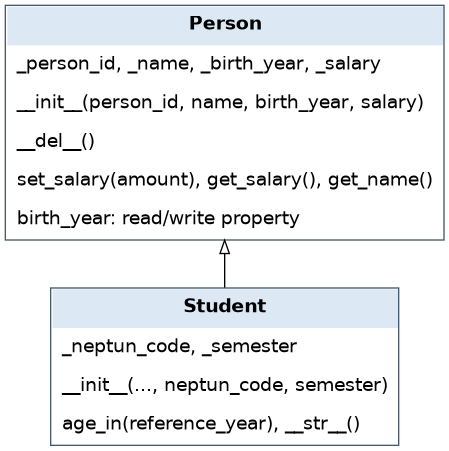


In [ ]:
# Optional: start measuring elapsed time for this exercise.
start_exercise(1)


In [ ]:
SOLUTIONS[1] = r"""
class Person:
    def __init__(self, person_id, name, birth_year, salary):
        pass

    def __del__(self):
        pass


"""


In [ ]:
check(1)


## Exercise 2 – Person: public methods and property (15 minutes)

Copy your Person class from Exercise 1. Add `set_salary(amount)` and `get_name()`. Reject a negative salary with ValueError; add `get_salary()` so callers can check the updated value without reading `_salary`. Use @property and @birth_year.setter for birth_year. Accept positive integer years only; raise ValueError otherwise. Use the same validation when initializing salary and birth_year. Demonstrate the public interface.

Write your code **inside the triple quotes**, then run this cell and the check cell below. Checks run your solution in a fresh namespace.

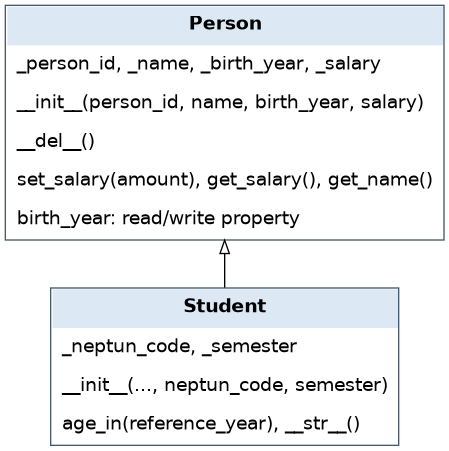


In [ ]:
# Optional: start measuring elapsed time for this exercise.
start_exercise(2)


In [ ]:
SOLUTIONS[2] = r"""
# Paste and extend your Person class here.

"""


In [ ]:
check(2)


## Exercise 3 – Student: inheritance (30 minutes)

Copy your Person class from Exercise 2. Define Student(Person) with parameters person_id, name, birth_year, salary, neptun_code, semester. Initialize Person with `super()`.`__init__`, and store the two new fields with leading underscores. Implement `age_in(reference_year)`, returning reference_year minus birth_year (year-based estimate), and `__str__`, returning 'Name (Neptun: CODE, semester: N)'. Test one Student instance through its public interface.

Write your code **inside the triple quotes**, then run this cell and the check cell below. Checks run your solution in a fresh namespace.

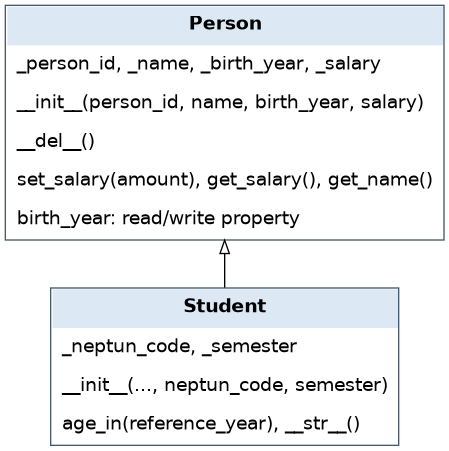


In [ ]:
# Optional: start measuring elapsed time for this exercise.
start_exercise(3)


In [ ]:
SOLUTIONS[3] = r"""
# Paste Person here, then define Student.

"""


In [ ]:
check(3)


## Exercise 4 – Shape: rectangle and circle (30 minutes)

Define Shape with non-public class constant `_PI` = 3.14159. Its `area()` and `perimeter()` raise NotImplementedError. Define Rectangle(width, height=None) and Circle(radius) as subclasses with non-public dimensions and overridden methods. A rectangle with no height is a square. Assume dimensions are positive. Use the inherited constant for circle calculations. Test a rectangle, a square and a circle through their public methods.

Write your code **inside the triple quotes**, then run this cell and the check cell below. Checks run your solution in a fresh namespace.

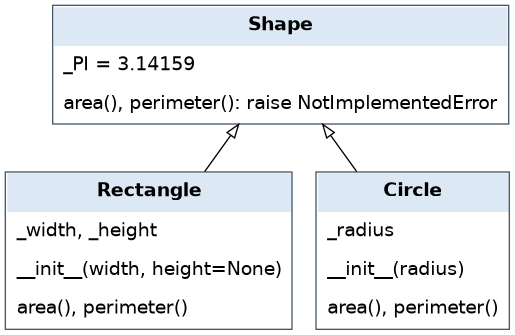


In [ ]:
# Optional: start measuring elapsed time for this exercise.
start_exercise(4)


In [ ]:
SOLUTIONS[4] = r"""
# Define Shape, Rectangle and Circle here.

"""


In [ ]:
check(4)


## Exercise 5 – Fraction: arithmetic operators (40 minutes)

Define Fraction(numerator, denominator=1) with non-public fields and read-only numerator and denominator properties. Use integer inputs. Raise ValueError for a zero denominator. Reduce each fraction with a loop-based GCD and keep the denominator positive. Implement `__str__` as numerator/denominator (also for denominator 1). Implement +, -, * and / between Fraction objects; return new instances and leave operands unchanged. Raise ZeroDivisionError when dividing by a fraction with numerator zero. Return NotImplemented for unsupported operand types. Try 1/2 and 3/4: the four operations should give 5/4, -1/4, 3/8 and 2/3. Fraction(4) minus Fraction(1, 2) should give 7/2.

Write your code **inside the triple quotes**, then run this cell and the check cell below. Checks run your solution in a fresh namespace.

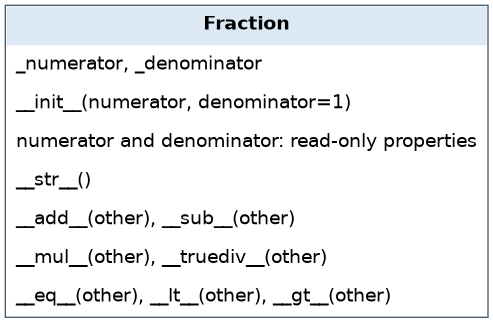


In [ ]:
# Optional: start measuring elapsed time for this exercise.
start_exercise(5)


In [ ]:
SOLUTIONS[5] = r"""
# Define Fraction here.

"""


In [ ]:
check(5)


## Exercise 6 – Fraction: comparison operators (20 minutes)

Copy your Fraction class from Exercise 5 and add `__eq__`, `__lt__` and `__gt__`. Compare fractions exactly using cross multiplication, without converting to float. Return NotImplemented for unsupported operands. Test equivalent fractions, different fractions and negative values. This is an in-class exercise.

Write your code **inside the triple quotes**, then run this cell and the check cell below. Checks run your solution in a fresh namespace.

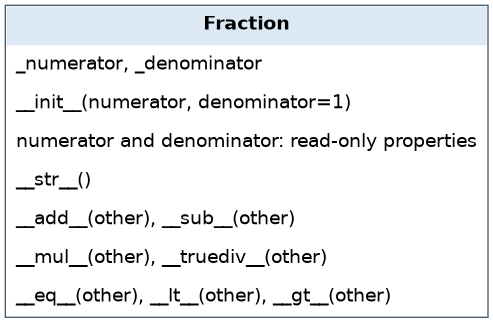


In [ ]:
# Optional: start measuring elapsed time for this exercise.
start_exercise(6)


In [ ]:
SOLUTIONS[6] = r"""
# Paste Fraction and add its three comparison methods.

"""


In [ ]:
check(6)


## Evaluate my work

Rerun your edited solution cells before evaluating. Entering your Neptun code sends your solutions, check counts and elapsed times to Azure. Press Enter instead to keep your results local. The optional timer measures elapsed time from its start cell through your last individual check, including breaks.


In [ ]:
evaluate_work()


In [ ]:
# Optional: estimated score and feedback for the saved evaluation.
request_ai()
